# Лабораторная работа: диагностика обучения MLP

**Цель:** обучить MLP для бинарной классификации `make_moons`, исследовать влияние активации, инициализации, глубины сети и заданных режимов оптимизации; проанализировать loss, accuracy и градиенты скрытых слоёв.

In [23]:
import os
import json
import random
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

# Каталоги результатов
RESULTS_DIR = Path("results")
FIGURES_DIR = Path("figures")
CHECKPOINTS_DIR = Path("checkpoints")
for directory in (RESULTS_DIR, FIGURES_DIR, CHECKPOINTS_DIR):
    directory.mkdir(exist_ok=True)

# По условию эксперименты выполняются на CPU
DEVICE = torch.device("cpu")
torch.set_num_threads(1)

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Device:", DEVICE)
print("torch threads:", torch.get_num_threads())

Python: 3.12.3
NumPy: 2.1.3
scikit-learn: 1.6.1
PyTorch: 2.6.0+cu124
Matplotlib: 3.10.1
Device: cpu
torch threads: 1


## 1. Подготовка выборок

In [37]:
X, y = make_moons(n_samples=2400, noise=0.25, random_state=2026)

X_dev, X_test_raw, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=2026,
    stratify=y
)

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    random_state=2026,
    stratify=y_dev
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

splits = {
    "train": (X_train, y_train),
    "validation": (X_val, y_val),
    "test": (X_test, y_test),
}
for name, (features, labels) in splits.items():
    unique, counts = np.unique(labels, return_counts=True)
    print(f"{name}: X={features.shape}, y={labels.shape}, "
          f"class distribution={dict(zip(unique.tolist(), counts.tolist()))}")

assert X_train.shape == (1440, 2)
assert X_val.shape == (480, 2)
assert X_test.shape == (480, 2)
for _, (_, labels) in splits.items():
    assert set(np.unique(labels)) == {0, 1}

print("\nTrain scaled feature means:", X_train.mean(axis=0))
print("Train scaled feature stds: ", X_train.std(axis=0))

train: X=(1440, 2), y=(1440,), class distribution={0: 720, 1: 720}
validation: X=(480, 2), y=(480,), class distribution={0: 240, 1: 240}
test: X=(480, 2), y=(480,), class distribution={0: 240, 1: 240}

Train scaled feature means: [2.59052039e-17 6.30514159e-16]
Train scaled feature stds:  [1. 1.]


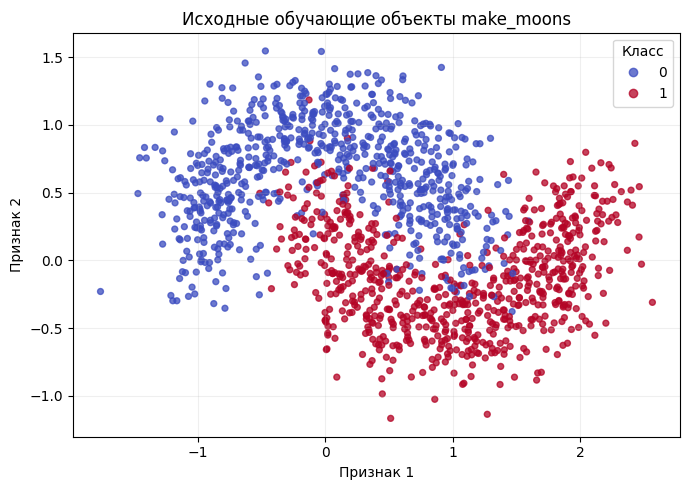

In [38]:
plt.figure(figsize=(7, 5))
scatter = plt.scatter(
    X_train_raw[:, 0], X_train_raw[:, 1],
    c=y_train, cmap="coolwarm", s=18, alpha=0.75
)
plt.xlabel("Признак 1")
plt.ylabel("Признак 2")
plt.title("Исходные обучающие объекты make_moons")
plt.legend(*scatter.legend_elements(), title="Класс")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_train_scatter.png", dpi=160)
plt.show()

## 2. MLP

Каждый скрытый слой имеет ширину 32. На выходе — линейный слой с двумя логитами. Число скрытых слоёв задаётся конфигурацией (1-6). Во всех скрытых слоях одного запуска используется одна активация.

Число параметров для сети с `L` скрытыми слоями ширины 32:
- первый скрытый Linear: `2·32 + 32`;
- остальные `L−1` скрытых Linear: `(32·32 + 32)` каждый;
- выходной Linear: `32·2 + 2`.

Итого: `(2·32+32) + (L−1)·(32·32+32) + (32·2+2)`.

In [39]:
class MLP(nn.Module):
    def __init__(self, input_dim=2, hidden_width=32, hidden_layers=6,
                 activation_name="relu"):
        super().__init__()
        if hidden_layers < 1:
            raise ValueError

        activation_map = {
            "sigmoid": nn.Sigmoid,
            "tanh": nn.Tanh,
            "relu": nn.ReLU,
        }
        if activation_name not in activation_map:
            raise ValueError

        layers = []
        in_features = input_dim
        self.hidden_linears = nn.ModuleList()

        for _ in range(hidden_layers):
            linear = nn.Linear(in_features, hidden_width)
            self.hidden_linears.append(linear)
            layers.extend([linear, activation_map[activation_name]()])
            in_features = hidden_width

        self.hidden_network = nn.Sequential(*layers)
        self.output_linear = nn.Linear(hidden_width, 2)

    def forward(self, x):
        x = self.hidden_network(x)
        return self.output_linear(x)


def initialize_model(model, hidden_init):
    for layer in model.hidden_linears:
        if hidden_init == "xavier":
            nn.init.xavier_normal_(layer.weight, gain=1.0)
        elif hidden_init == "he":
            nn.init.kaiming_normal_(
                layer.weight, mode="fan_in", nonlinearity="relu"
            )
        else:
            raise ValueError
        nn.init.zeros_(layer.bias)

    nn.init.xavier_normal_(model.output_linear.weight, gain=1.0)
    nn.init.zeros_(model.output_linear.bias)


def count_parameters_formula(hidden_layers, width=32, input_dim=2, output_dim=2):
    first = input_dim * width + width
    middle = (hidden_layers - 1) * (width * width + width)
    output = width * output_dim + output_dim
    return first + middle + output


def accuracy_from_logits(logits, targets):
    predictions = logits.argmax(dim=1)
    return (predictions == targets).float().mean().item()


def evaluate(model, features, labels, criterion):
    model.eval()
    with torch.no_grad():
        logits = model(features)
        loss = criterion(logits, labels).item()
        accuracy = accuracy_from_logits(logits, labels)
    return loss, accuracy


def evaluate_and_record(model, epoch, config, seed, criterion,
                        train_features, train_labels, val_features, val_labels):
    train_loss, train_accuracy = evaluate(
        model, train_features, train_labels, criterion
    )
    val_loss, val_accuracy = evaluate(
        model, val_features, val_labels, criterion
    )
    values = [train_loss, train_accuracy, val_loss, val_accuracy]
    if not np.all(np.isfinite(values)):
        raise ValueError
    return {
        "config": config,
        "seed": seed,
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
    }


def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    for batch_features, batch_labels in loader:
        optimizer.zero_grad()
        logits = model(batch_features)
        loss = criterion(logits, batch_labels)
        loss.backward()
        optimizer.step()


def gradient_probe(model, probe_features, probe_labels, criterion):
    model.zero_grad(set_to_none=True)
    model.eval()
    logits = model(probe_features)
    loss = criterion(logits, probe_labels)
    loss.backward()

    norms = []
    for layer_index, layer in enumerate(model.hidden_linears, start=1):
        grad = layer.weight.grad
        if grad is None:
            norms.append({
                "layer": layer_index,
                "gradient_norm": np.nan,
                "gradient_status": "missing"
            })
        else:
            norm = torch.linalg.vector_norm(grad).item()
            norms.append({
                "layer": layer_index,
                "gradient_norm": norm,
                "gradient_status": "finite" if np.isfinite(norm) else "non-finite"
            })

    model.zero_grad(set_to_none=True)
    return norms

### Проверка

In [40]:
torch.manual_seed(11)
check_model = MLP(hidden_layers=6, activation_name="relu").to(DEVICE)
initialize_model(check_model, "he")

check_x = torch.tensor(X_train[:8], dtype=torch.float32, device=DEVICE)
check_y = torch.tensor(y_train[:8], dtype=torch.long, device=DEVICE)
criterion = nn.CrossEntropyLoss(reduction="mean")

check_logits = check_model(check_x)
check_loss = criterion(check_logits, check_y)
print("Input shape:", tuple(check_x.shape))
print("Output shape:", tuple(check_logits.shape))
print("Loss shape:", tuple(check_loss.shape))

formula_count = count_parameters_formula(hidden_layers=6)
actual_count = sum(parameter.numel() for parameter in check_model.parameters())
print("Parameters by formula:", formula_count)
print("Parameters by PyTorch:", actual_count)
assert formula_count == actual_count

check_model.zero_grad(set_to_none=True)
check_loss.backward()
for i, layer in enumerate(check_model.hidden_linears, start=1):
    grad = layer.weight.grad
    assert grad is not None
    assert grad.shape == layer.weight.shape
    assert torch.isfinite(grad).all()
    print(f"Hidden layer {i}: weight={tuple(layer.weight.shape)}, "
          f"grad={tuple(grad.shape)}, grad finite={torch.isfinite(grad).all().item()}")
check_model.zero_grad(set_to_none=True)

Input shape: (8, 2)
Output shape: (8, 2)
Loss shape: ()
Parameters by formula: 5442
Parameters by PyTorch: 5442
Hidden layer 1: weight=(32, 2), grad=(32, 2), grad finite=True
Hidden layer 2: weight=(32, 32), grad=(32, 32), grad finite=True
Hidden layer 3: weight=(32, 32), grad=(32, 32), grad finite=True
Hidden layer 4: weight=(32, 32), grad=(32, 32), grad finite=True
Hidden layer 5: weight=(32, 32), grad=(32, 32), grad finite=True
Hidden layer 6: weight=(32, 32), grad=(32, 32), grad finite=True


## 3. Эксперименты A–F

In [42]:
CONFIGS = {
    "A": {"hidden_layers": 6, "activation": "sigmoid", "hidden_init": "xavier",
          "optimizer": "adam", "lr": 0.003},
    "B": {"hidden_layers": 6, "activation": "tanh", "hidden_init": "xavier",
          "optimizer": "adam", "lr": 0.003},
    "C": {"hidden_layers": 6, "activation": "relu", "hidden_init": "xavier",
          "optimizer": "adam", "lr": 0.003},
    "D": {"hidden_layers": 6, "activation": "relu", "hidden_init": "he",
          "optimizer": "adam", "lr": 0.003},
    "E": {"hidden_layers": 6, "activation": "relu", "hidden_init": "he",
          "optimizer": "sgd", "lr": 0.05},
    "F": {"hidden_layers": 1, "activation": "relu", "hidden_init": "he",
          "optimizer": "adam", "lr": 0.003},
}

X_train_t = torch.tensor(X_train, dtype=torch.float32, device=DEVICE)
y_train_t = torch.tensor(y_train, dtype=torch.long, device=DEVICE)
X_val_t = torch.tensor(X_val, dtype=torch.float32, device=DEVICE)
y_val_t = torch.tensor(y_val, dtype=torch.long, device=DEVICE)
X_test_t = torch.tensor(X_test, dtype=torch.float32, device=DEVICE)
y_test_t = torch.tensor(y_test, dtype=torch.long, device=DEVICE)

probe_x = X_train_t[:128]
probe_y = y_train_t[:128]
assert probe_x.shape == (128, 2)

In [43]:
all_metrics = []
all_gradient_rows = []
models = {}
histories = {}

for config_name, settings in CONFIGS.items():
    for seed in (11, 29):
        print(f"\n=== Config {config_name}, seed {seed} ===")

        torch.manual_seed(seed)
        model = MLP(
            hidden_layers=settings["hidden_layers"],
            activation_name=settings["activation"]
        ).to(DEVICE)
        initialize_model(model, settings["hidden_init"])

        parameter_count = sum(p.numel() for p in model.parameters())
        formula_count = count_parameters_formula(settings["hidden_layers"])
        assert parameter_count == formula_count
        print("Parameter count:", parameter_count)

        if settings["optimizer"] == "adam":
            optimizer = torch.optim.Adam(model.parameters(), lr=settings["lr"])
        elif settings["optimizer"] == "sgd":
            optimizer = torch.optim.SGD(
                model.parameters(), lr=settings["lr"], momentum=0
            )
        else:
            raise ValueError(settings["optimizer"])

        criterion = nn.CrossEntropyLoss(reduction="mean")
        generator = torch.Generator().manual_seed(10000 + seed)
        dataset = TensorDataset(X_train_t, y_train_t)
        loader = DataLoader(
            dataset, batch_size=128, shuffle=True,
            generator=generator, num_workers=0
        )

        run_history = []
        run_history.append(evaluate_and_record(
            model, 0, config_name, seed, criterion,
            X_train_t, y_train_t, X_val_t, y_val_t
        ))

        if config_name in {"A", "C", "D"}:
            for row in gradient_probe(model, probe_x, probe_y, criterion):
                all_gradient_rows.append({
                    "config": config_name, "seed": seed, "epoch": 0, **row
                })

        for epoch in range(1, 101):
            train_one_epoch(model, loader, criterion, optimizer)
            run_history.append(evaluate_and_record(
                model, epoch, config_name, seed, criterion,
                X_train_t, y_train_t, X_val_t, y_val_t
            ))

            if config_name in {"A", "C", "D"} and epoch in {20, 100}:
                for row in gradient_probe(model, probe_x, probe_y, criterion):
                    all_gradient_rows.append({
                        "config": config_name, "seed": seed,
                        "epoch": epoch, **row
                    })

        key = (config_name, seed)
        models[key] = model
        histories[key] = pd.DataFrame(run_history)
        all_metrics.extend(run_history)

        assert all(torch.isfinite(p).all() for p in model.parameters())
        print("Final train loss / accuracy:",
              run_history[-1]["train_loss"], run_history[-1]["train_accuracy"])
        print("Final val loss / accuracy:",
              run_history[-1]["val_loss"], run_history[-1]["val_accuracy"])

metrics_df = pd.DataFrame(all_metrics)
gradients_df = pd.DataFrame(all_gradient_rows)

metrics_df.to_csv(RESULTS_DIR / "metrics_all_runs.csv", index=False)
gradients_df.to_csv(RESULTS_DIR / "gradient_norms.csv", index=False)

print("\nMetrics rows:", len(metrics_df), "(expected 12 * 101 =", 12 * 101, ")")
print("Gradient rows:", len(gradients_df))
display(metrics_df.head())
display(gradients_df.head())


=== Config A, seed 11 ===
Parameter count: 5442
Final train loss / accuracy: 0.15045230090618134 0.9458333253860474
Final val loss / accuracy: 0.19074994325637817 0.9166666865348816

=== Config A, seed 29 ===
Parameter count: 5442
Final train loss / accuracy: 0.14030931890010834 0.9458333253860474
Final val loss / accuracy: 0.17710281908512115 0.9166666865348816

=== Config B, seed 11 ===
Parameter count: 5442
Final train loss / accuracy: 0.14670567214488983 0.9465277791023254
Final val loss / accuracy: 0.20339518785476685 0.9125000238418579

=== Config B, seed 29 ===
Parameter count: 5442
Final train loss / accuracy: 0.14358116686344147 0.9486111402511597
Final val loss / accuracy: 0.18927134573459625 0.918749988079071

=== Config C, seed 11 ===
Parameter count: 5442
Final train loss / accuracy: 0.12093988060951233 0.9513888955116272
Final val loss / accuracy: 0.18028075993061066 0.925000011920929

=== Config C, seed 29 ===
Parameter count: 5442
Final train loss / accuracy: 0.1254582

,config,seed,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,A,11,0,0.696938,0.500000,0.696936,0.500000
1,A,11,1,0.693496,0.500000,0.693500,0.500000
2,A,11,2,0.692383,0.500000,0.692393,0.500000
3,A,11,3,0.694605,0.500000,0.694611,0.500000
4,A,11,4,0.684206,0.691667,0.684304,0.658333


,config,seed,epoch,layer,gradient_norm,gradient_status
0,A,11,0,1,0.000152,finite
1,A,11,0,2,0.000311,finite
2,A,11,0,3,0.000901,finite
3,A,11,0,4,0.003209,finite
4,A,11,0,5,0.017441,finite


## 4. Сравнительная таблица и графики A–F (seed 11)

В таблице приведены четыре метрики эпохи 100 для каждого seed. Дополнительно рассчитывается средний `val_loss` по двум seed

In [44]:
final_metrics = metrics_df[metrics_df["epoch"] == 100].copy()
comparison_table = final_metrics[
    ["config", "seed", "train_loss", "train_accuracy", "val_loss", "val_accuracy"]
].sort_values(["config", "seed"]).reset_index(drop=True)

mean_val_loss = (
    final_metrics.groupby("config", as_index=False)["val_loss"]
    .mean()
    .rename(columns={"val_loss": "mean_val_loss"})
)
comparison_table.to_csv(RESULTS_DIR / "metrics_epoch_100.csv", index=False)
mean_val_loss.to_csv(RESULTS_DIR / "mean_validation_loss.csv", index=False)

display(comparison_table)
display(mean_val_loss)

,config,seed,train_loss,train_accuracy,val_loss,val_accuracy
0,A,11,0.150452,0.945833,0.190750,0.916667
1,A,29,0.140309,0.945833,0.177103,0.916667
2,B,11,0.146706,0.946528,0.203395,0.912500
3,B,29,0.143581,0.948611,0.189271,0.918750
4,C,11,0.120940,0.951389,0.180281,0.925000
5,C,29,0.125458,0.948611,0.207281,0.916667
6,D,11,0.109051,0.952778,0.219230,0.908333
7,D,29,0.110387,0.956944,0.225594,0.897917
8,E,11,0.234814,0.900000,0.326052,0.862500
9,E,29,0.307365,0.863889,0.359698,0.843750


,config,mean_val_loss
0,A,0.183926
1,B,0.196333
2,C,0.193781
3,D,0.222412
4,E,0.342875
5,F,0.167705


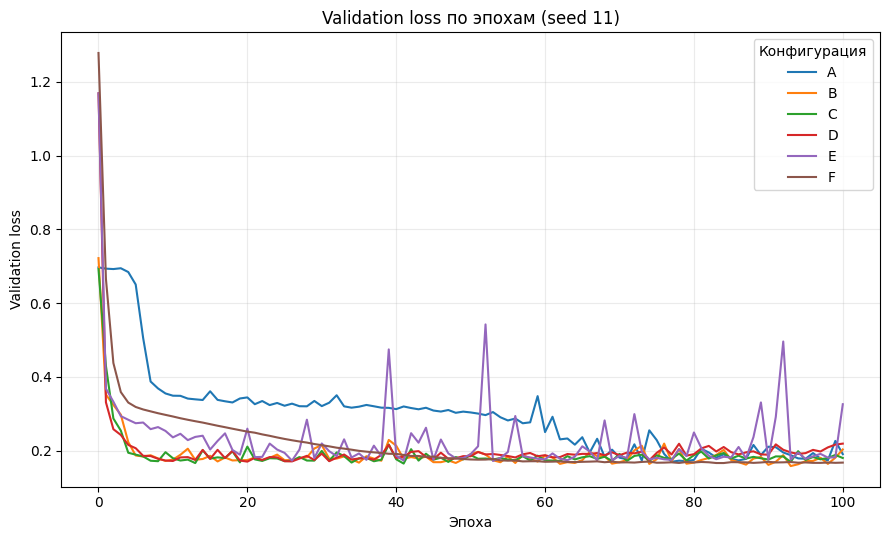

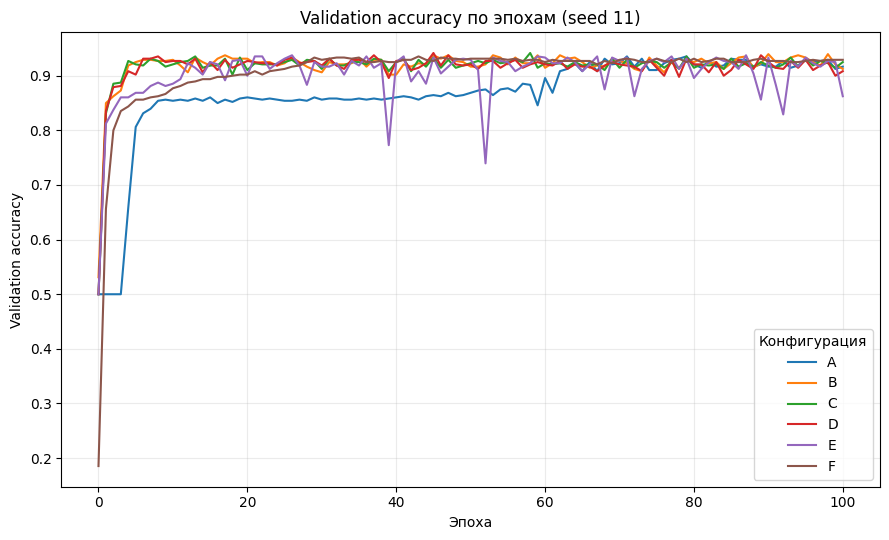

In [54]:
plt.figure(figsize=(9, 5.5))
for config_name in CONFIGS:
    frame = histories[(config_name, 11)]
    plt.plot(frame["epoch"], frame["val_loss"], label=config_name)
plt.xlabel("Эпоха")
plt.ylabel("Validation loss")
plt.title("Validation loss по эпохам (seed 11)")
plt.legend(title="Конфигурация")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_validation_loss_seed11.png", dpi=160)
plt.show()

plt.figure(figsize=(9, 5.5))
for config_name in CONFIGS:
    frame = histories[(config_name, 11)]
    plt.plot(frame["epoch"], frame["val_accuracy"], label=config_name)
plt.xlabel("Эпоха")
plt.ylabel("Validation accuracy")
plt.title("Validation accuracy по эпохам (seed 11)")
plt.legend(title="Конфигурация")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_validation_accuracy_seed11.png", dpi=160)
plt.show()

### 4.1. Сопоставление seed 11 и seed 29

In [47]:
selected_epochs = metrics_df[metrics_df["epoch"].isin([0, 20, 100])].copy()
seed_dynamics = selected_epochs[
    ["config", "seed", "epoch", "train_loss", "train_accuracy", "val_loss", "val_accuracy"]
].sort_values(["config", "seed", "epoch"])
display(seed_dynamics)
seed_dynamics.to_csv(RESULTS_DIR / "metrics_selected_epochs.csv", index=False)

,config,seed,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,A,11,0,0.696938,0.500000,0.696936,0.500000
20,A,11,20,0.337007,0.863194,0.344482,0.860417
100,A,11,100,0.150452,0.945833,0.190750,0.916667
101,A,29,0,0.713032,0.500000,0.713032,0.500000
121,A,29,20,0.328808,0.861111,0.327096,0.856250
201,A,29,100,0.140309,0.945833,0.177103,0.916667
202,B,11,0,0.723894,0.541667,0.722032,0.531250
222,B,11,20,0.157936,0.936111,0.174530,0.931250
302,B,11,100,0.146706,0.946528,0.203395,0.912500
303,B,29,0,0.553319,0.718056,0.552536,0.741667


## 5. Диагностика градиентов скрытых слоёв

,config,seed,epoch,layer,gradient_norm,gradient_status
0,A,11,0,1,0.000152,finite
1,A,11,0,2,0.000311,finite
2,A,11,0,3,0.000901,finite
3,A,11,0,4,0.003209,finite
4,A,11,0,5,0.017441,finite
...,...,...,...,...,...,...
103,D,29,100,2,0.437899,finite
104,D,29,100,3,0.302207,finite
105,D,29,100,4,0.230496,finite
106,D,29,100,5,0.143592,finite


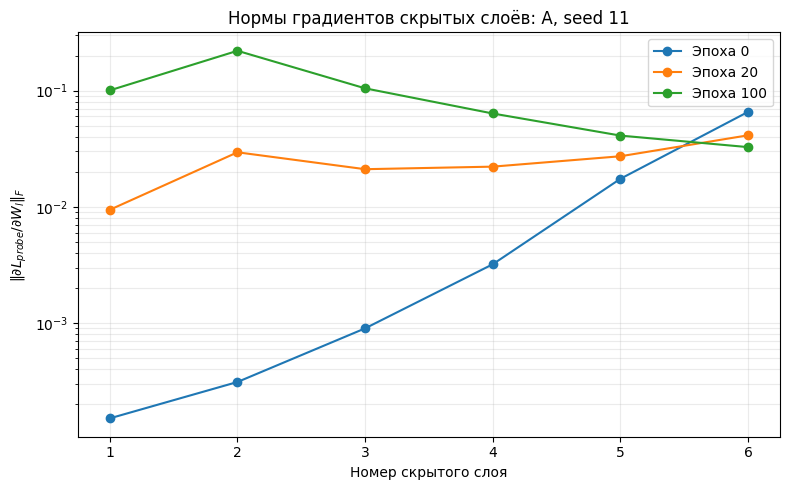

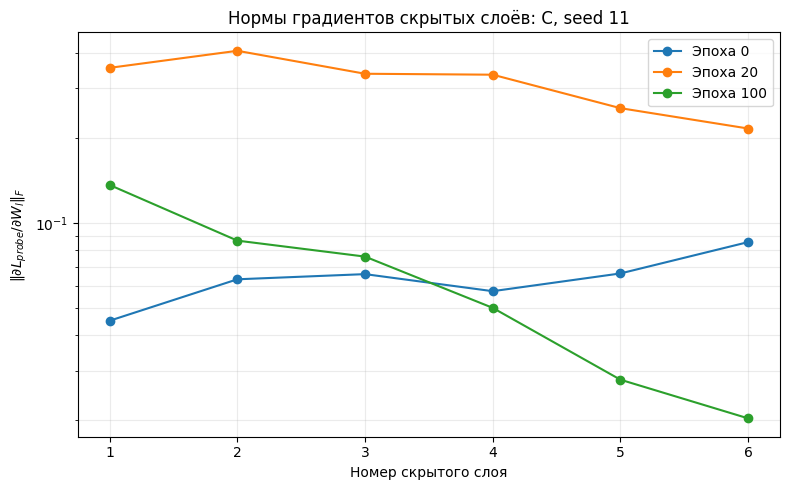

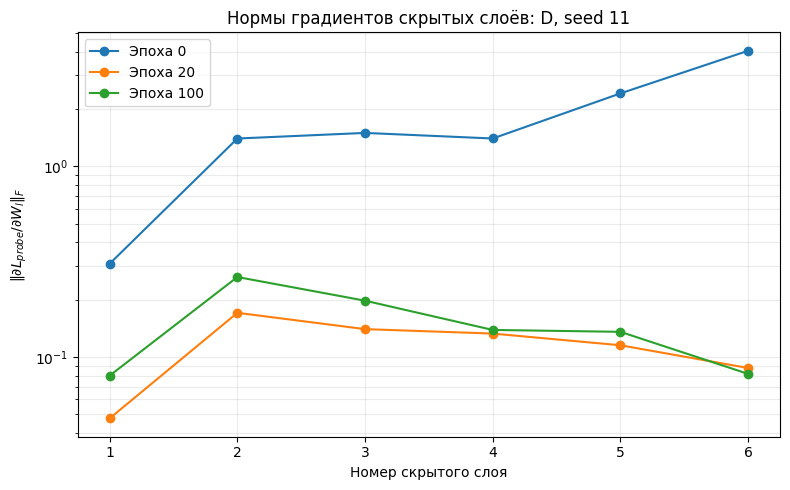

,config,seed,epoch,layer,gradient_norm,gradient_status


In [49]:
gradient_values = gradients_df[
    ["config", "seed", "epoch", "layer", "gradient_norm", "gradient_status"]
].sort_values(["config", "seed", "epoch", "layer"])
display(gradient_values)
gradient_values.to_csv(RESULTS_DIR / "gradient_norms_detailed.csv", index=False)

for config_name in ("A", "C", "D"):
    subset = gradients_df[
        (gradients_df["config"] == config_name) &
        (gradients_df["seed"] == 11)
    ].copy()

    plt.figure(figsize=(8, 5))
    for epoch in (0, 20, 100):
        curve = subset[subset["epoch"] == epoch].sort_values("layer")
        positive = curve["gradient_norm"] > 0
        plt.plot(
            curve.loc[positive, "layer"],
            curve.loc[positive, "gradient_norm"],
            marker="o", label=f"Эпоха {epoch}"
        )

    plt.yscale("log")
    plt.xlabel("Номер скрытого слоя")
    plt.ylabel(r"$\|\partial L_{probe}/\partial W_l\|_F$")
    plt.title(f"Нормы градиентов скрытых слоёв: {config_name}, seed 11")
    plt.xticks(range(1, CONFIGS[config_name]["hidden_layers"] + 1))
    plt.legend()
    plt.grid(alpha=0.25, which="both")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"04_gradient_{config_name}_seed11.png", dpi=160)
    plt.show()

special_gradients = gradients_df[
    (~np.isfinite(gradients_df["gradient_norm"])) |
    (gradients_df["gradient_norm"] == 0) |
    (gradients_df["gradient_status"] != "finite")
]
display(special_gradients)

## 6. Выбор конфигурации и итоговая оценка на test

In [50]:
config_order = {name: index for index, name in enumerate(CONFIGS.keys())}
ranking = mean_val_loss.copy()
ranking["config_order"] = ranking["config"].map(config_order)
ranking = ranking.sort_values(
    ["mean_val_loss", "config_order"], ascending=[True, True]
).reset_index(drop=True)

selected_config = ranking.iloc[0]["config"]
selected_runs = final_metrics[final_metrics["config"] == selected_config].copy()
selected_runs = selected_runs.sort_values(
    ["val_loss", "seed"], ascending=[True, True]
)
selected_seed = int(selected_runs.iloc[0]["seed"])

selected_model = models[(selected_config, selected_seed)]
selected_history = histories[(selected_config, selected_seed)].copy()

print("Ranking:")
display(ranking[["config", "mean_val_loss"]])
print("Selected config:", selected_config)
print("Selected seed:", selected_seed)
print("Selected validation loss:",
      float(selected_runs.iloc[0]["val_loss"]))

test_loss, test_accuracy = evaluate(
    selected_model, X_test_t, y_test_t, nn.CrossEntropyLoss(reduction="mean")
)
print(f"Final test loss: {test_loss:.6f}")
print(f"Final test accuracy: {test_accuracy:.6f}")

torch.save(
    {
        "config": selected_config,
        "seed": selected_seed,
        "settings": CONFIGS[selected_config],
        "model_state_dict": selected_model.state_dict(),
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
    },
    CHECKPOINTS_DIR / "selected_model.pt"
)

selection_summary = {
    "selected_config": selected_config,
    "selected_seed": selected_seed,
    "selected_val_loss": float(selected_runs.iloc[0]["val_loss"]),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
}
with open(RESULTS_DIR / "selection_and_test.json", "w", encoding="utf-8") as file:
    json.dump(selection_summary, file, ensure_ascii=False, indent=2)

Ranking:


,config,mean_val_loss
0,F,0.167705
1,A,0.183926
2,C,0.193781
3,B,0.196333
4,D,0.222412
5,E,0.342875


Selected config: F
Selected seed: 29
Selected validation loss: 0.16762325167655945
Final test loss: 0.131385
Final test accuracy: 0.950000


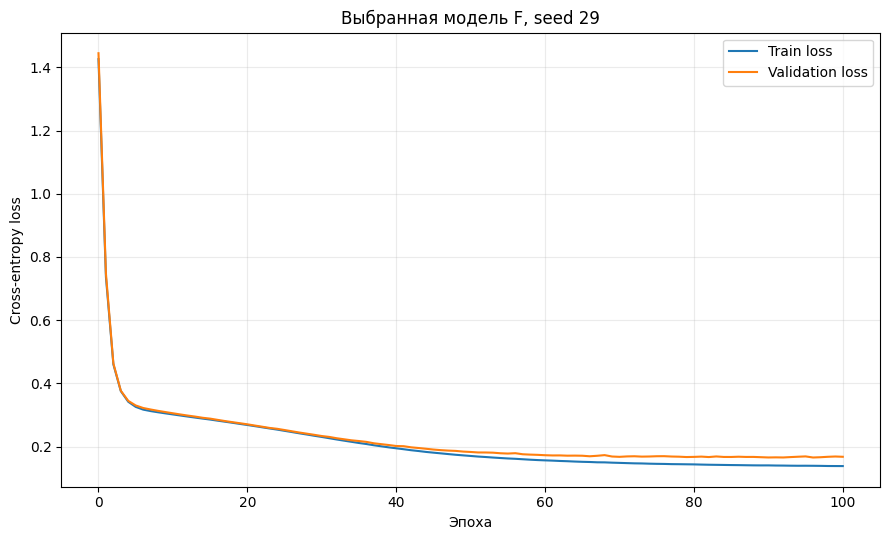

In [51]:
plt.figure(figsize=(9, 5.5))
plt.plot(selected_history["epoch"], selected_history["train_loss"], label="Train loss")
plt.plot(selected_history["epoch"], selected_history["val_loss"], label="Validation loss")
plt.xlabel("Эпоха")
plt.ylabel("Cross-entropy loss")
plt.title(f"Выбранная модель {selected_config}, seed {selected_seed}")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_selected_train_validation_loss.png", dpi=160)
plt.show()